# 广发证券 HMM 周择时研报复现

复现对象：广发证券《探寻西蒙斯投资之道：基于 HMM 模型的周择时策略研究》（2010-06-17）。

这个 notebook 从一开始就按研报图表 6/7 的思路做成参数可调模式：

- 输入变量组合：`X3 X4`、`X2 X3 X4`、`X1 X2 X3 X4`
- 样本长度：`5, 10, 15, 20` 个交易日
- 训练样本数量：`300, 400, 500`
- 模型：连续高斯 HMM，隐状态数 `Q=3`
- 预测：用过去 `T` 个交易日的日频特征序列预测未来 5 个交易日涨跌/涨跌平

数据源说明：默认使用 AkShare 的新浪指数日线接口 `stock_zh_index_daily("sh000300")`，避开东方财富 `push2` 接口的代理断连问题。若你想用东方财富直连，可把 `DATA_SOURCE` 改成 `eastmoney_direct`；若你有 Wind/Choice/聚宽/米筐导出的 CSV，可以在参数区切换为本地数据。

In [1]:
# 如本地已安装依赖，可跳过本单元。
%pip install -q akshare hmmlearn scikit-learn matplotlib openpyxl


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import json
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 1. 全局参数

你主要改这里就可以：

- `DATA_SOURCE`: `akshare` 或 `local_csv`
- `LOCAL_CSV`: 本地 CSV 路径
- `FEATURE_SETS`: 输入变量组合
- `SEQUENCE_LENS`: 样本长度
- `TRAIN_WINDOWS`: 训练样本数量
- `RUN_SENSITIVITY`: 是否跑图表 6/7 式敏感性分析

说明：原研报的资金流变量来自高频资金流。本 notebook 先用日线 OHLC/成交额构造代理变量，后续可以把 `build_features()` 中的 `X2` 和 `amount` 定义替换成真实高频资金流。

In [25]:
@dataclass
class Config:
    symbol: str = "000300"                 # 沪深 300 指数
    start_date: str = "20050408"
    end_date: str = "20100430"
    forecast_horizon: int = 5               # 预测未来 5 个交易日，近似下一周
    n_components: int = 3                   # HMM 隐状态数 Q=3
    min_class_samples: int = 8
    random_state: int = 42
    transaction_fee: float = 0.005          # 单边 0.5% 手续费

cfg = Config()

DATA_SOURCE = "akshare_sina"               # 可选："akshare_sina"、"eastmoney_direct"、"akshare_eastmoney" 或 "local_csv"
LOCAL_CSV = None                            # 例如："/path/to/hs300_daily.csv"
DISABLE_PROXY_FOR_CN_DATA = True            # 解决 VPN/代理导致的东方财富 ProxyError

# 研报图表 6/7 的参数网格
SEQUENCE_LENS = [5, 10, 15, 20]
TRAIN_WINDOWS = [300, 400, 500]
FEATURE_SETS = {
    "X3_X4": ["x3_total_money_chg", "x4_total_money_zscore"],
    "X2_X3_X4": ["x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"],
    "X1_X2_X3_X4": ["x1_ret", "x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"],
}

# 样本外区间：对应研报两类/三类模型
BINARY_OOS = ("2007-12-19", "2010-04-29")
TERNARY_OOS = ("2008-05-12", "2010-04-29")
TERNARY_FLAT_THRESHOLD = 0.02

RUN_SENSITIVITY = True

# 敏感性分析后，可以用最佳参数自动回测；也可以手动指定。
USE_BEST_PARAM_FROM_SENSITIVITY = True
MANUAL_FEATURE_SET = "X1_X2_X3_X4"
MANUAL_SEQUENCE_LEN = 5
MANUAL_TRAIN_WINDOW = 400

## 2. 读取数据

默认：使用 AkShare 的 `stock_zh_index_daily(symbol="sh000300")`，数据来自新浪指数日线接口，避开东方财富 `push2` 接口。若想使用东方财富直连，可在参数区设置 `DATA_SOURCE = "eastmoney_direct"`。

本地 CSV 至少需要日期和收盘价，最好包含 `open/high/low/close/volume/amount` 或中文列名 `日期/开盘/最高/最低/收盘/成交量/成交额`。

In [4]:
def normalize_price_columns(df: pd.DataFrame) -> pd.DataFrame:
    mapping = {
        "日期": "date", "开盘": "open", "最高": "high", "最低": "low", "收盘": "close",
        "成交量": "volume", "成交额": "amount", "涨跌幅": "pct_change",
        "date": "date", "open": "open", "high": "high", "low": "low", "close": "close",
        "volume": "volume", "amount": "amount",
    }
    out = df.rename(columns={c: mapping.get(c, c) for c in df.columns}).copy()
    out["date"] = pd.to_datetime(out["date"])
    for col in ["open", "high", "low", "close", "volume", "amount"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    if "amount" not in out.columns or out["amount"].isna().all():
        out["amount"] = out["close"] * out.get("volume", 1.0)
    keep = ["date", "open", "high", "low", "close", "volume", "amount"]
    return out[[c for c in keep if c in out.columns]].sort_values("date").dropna(subset=["date", "close"])


def clear_proxy_env():
    """AkShare/requests 会读取环境变量中的代理；VPN 打开时这里常导致 ProxyError。"""
    for key in [
        "HTTP_PROXY", "HTTPS_PROXY", "ALL_PROXY",
        "http_proxy", "https_proxy", "all_proxy",
    ]:
        os.environ.pop(key, None)


def load_eastmoney_direct(cfg: Config, disable_proxy: bool = True) -> pd.DataFrame:
    url = (
        "https://push2his.eastmoney.com/api/qt/stock/kline/get"
        f"?secid=1.{cfg.symbol}"
        "&fields1=f1,f2,f3,f4,f5,f6"
        "&fields2=f51,f52,f53,f54,f55,f56,f57,f58,f59,f60,f61"
        f"&klt=101&fqt=0&beg={cfg.start_date}&end={cfg.end_date}"
    )
    opener = urllib.request.build_opener(urllib.request.ProxyHandler({})) if disable_proxy else urllib.request.build_opener()
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with opener.open(req, timeout=30) as resp:
        payload = json.loads(resp.read().decode("utf-8"))
    klines = payload.get("data", {}).get("klines", [])
    if not klines:
        raise RuntimeError(f"东方财富接口未返回行情数据: {payload}")
    rows = [line.split(",") for line in klines]
    out = pd.DataFrame(rows, columns=[
        "date", "open", "close", "high", "low", "volume", "amount",
        "amplitude", "pct_change", "change", "turnover",
    ])
    return normalize_price_columns(out)


def load_hs300_daily(
    cfg: Config,
    data_source: str = "akshare_sina",
    local_csv: str | None = None,
    disable_proxy: bool = True,
) -> pd.DataFrame:
    if disable_proxy:
        clear_proxy_env()
    if data_source == "local_csv":
        if not local_csv:
            raise ValueError("DATA_SOURCE='local_csv' 时必须填写 LOCAL_CSV")
        return normalize_price_columns(pd.read_csv(local_csv))
    if data_source == "akshare_sina":
        import akshare as ak
        raw = ak.stock_zh_index_daily(symbol="sh000300")
        raw = normalize_price_columns(raw)
        start = pd.Timestamp(cfg.start_date)
        end = pd.Timestamp(cfg.end_date)
        return raw[(raw["date"] >= start) & (raw["date"] <= end)].copy()
    if data_source == "eastmoney_direct":
        return load_eastmoney_direct(cfg, disable_proxy=disable_proxy)
    if data_source == "akshare_eastmoney":
        import akshare as ak
        raw = ak.index_zh_a_hist(
            symbol=cfg.symbol,
            period="daily",
            start_date=cfg.start_date,
            end_date=cfg.end_date,
        )
        return normalize_price_columns(raw)
    raise ValueError("DATA_SOURCE must be 'akshare_sina', 'eastmoney_direct', 'akshare_eastmoney' or 'local_csv'")


daily = load_hs300_daily(cfg, DATA_SOURCE, LOCAL_CSV, DISABLE_PROXY_FOR_CN_DATA)
print(daily.head())
print(daily.tail())
print(daily.shape)

          date      open      high      low     close      volume  \
782 2005-04-08   984.665  1003.699  979.529  1003.445  1476252600   
783 2005-04-11  1003.879  1008.735  992.773   995.421  1593606600   
784 2005-04-12   993.711   993.711  978.204   978.697  1022619300   
785 2005-04-13   987.950  1006.499  987.950  1000.900  1607168700   
786 2005-04-14  1004.640  1006.416  985.578   986.975  1294571000   

           amount  
782  1.481338e+12  
783  1.586309e+12  
784  1.000834e+12  
785  1.608615e+12  
786  1.277709e+12  
           date      open      high       low     close      volume  \
2010 2010-04-26  3195.457  3207.715  3168.374  3171.997  5089420000   
2011 2010-04-27  3163.101  3163.101  3060.854  3108.409  6529657600   
2012 2010-04-28  3080.324  3122.115  3062.085  3097.353  4599540800   
2013 2010-04-29  3114.941  3130.696  3059.796  3060.064  4826097200   
2014 2010-04-30  3060.120  3068.127  3014.069  3067.365  5447788000   

            amount  
2010  1.614362e+1

## 3. 构造 `X1-X4`

研报变量：

- `X1`: 股票日收益率
- `X2`: 资金日净流入占当日所有流动资金比例
- `X3`: 日总流动资金环比
- `X4`: 标准化日总流动资金

当前代理版本：

- `日总资金 = 成交额 amount`
- `X2` 用日线资金压力代理：`((close-low)-(high-close))/(high-low)`，类似 close location value
- `X3 = amount.pct_change()`
- `X4 = (amount - 过去 250 日均值) / 过去 250 日标准差`

In [5]:
def build_features(daily: pd.DataFrame) -> pd.DataFrame:
    df = daily.copy()
    df["x1_ret"] = df["close"].pct_change()

    price_range = (df["high"] - df["low"]).replace(0, np.nan)
    df["x2_net_money_ratio_proxy"] = ((df["close"] - df["low"]) - (df["high"] - df["close"])) / price_range
    df["x2_net_money_ratio_proxy"] = df["x2_net_money_ratio_proxy"].clip(-1, 1).fillna(0)

    df["x3_total_money_chg"] = df["amount"].pct_change().replace([np.inf, -np.inf], np.nan)
    rolling_mean = df["amount"].rolling(250, min_periods=120).mean()
    rolling_std = df["amount"].rolling(250, min_periods=120).std()
    df["x4_total_money_zscore"] = (df["amount"] - rolling_mean) / rolling_std

    all_feature_cols = ["x1_ret", "x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"]
    df = df.dropna(subset=all_feature_cols + ["close"]).reset_index(drop=True)
    return df


feat = build_features(daily)
feat[["date", "close", "amount", "x1_ret", "x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"]].head()

,date,close,amount,x1_ret,x2_net_money_ratio_proxy,x3_total_money_chg,x4_total_money_zscore
0,2005-09-29,915.975,1.093581e+12,0.013562,1.000000,0.367284,-0.310449
1,2005-09-30,917.392,8.257843e+11,0.001547,0.512476,-0.244880,-0.773937
2,2005-10-10,907.321,6.495013e+11,-0.010978,-0.914626,-0.213473,-1.073343
3,2005-10-11,919.720,7.135459e+11,0.013666,0.990350,0.098606,-0.953668
4,2005-10-12,923.485,1.127469e+12,0.004094,0.401400,0.580093,-0.227378


## 4. 样本、模型、预测函数

每个样本是一段 `T x 特征数` 的日频序列，标签是随后 5 个交易日收益：

- 两类：未来 5 日收益大于 0 为 `up`，否则为 `down`
- 三类：未来 5 日收益大于 2% 为 `up`，小于 -2% 为 `down`，中间为 `flat`

In [6]:
def make_labeled_sequences(
    df: pd.DataFrame,
    feature_cols: list[str],
    sequence_len: int = 5,
    horizon: int = 5,
    mode: str = "binary",
    flat_threshold: float = 0.02,
) -> pd.DataFrame:
    rows = []
    values = df[feature_cols].to_numpy(float)
    close = df["close"].to_numpy(float)
    dates = df["date"].to_numpy()
    n = len(df)

    for start in range(0, n - sequence_len - horizon + 1):
        input_end = start + sequence_len - 1
        label_end = start + sequence_len + horizon - 1
        future_ret = close[label_end] / close[input_end] - 1
        if mode == "binary":
            label = "up" if future_ret > 0 else "down"
        elif mode == "ternary":
            if future_ret > flat_threshold:
                label = "up"
            elif future_ret < -flat_threshold:
                label = "down"
            else:
                label = "flat"
        else:
            raise ValueError("mode must be binary or ternary")

        rows.append({
            "start_idx": start,
            "input_end_idx": input_end,
            "label_end_idx": label_end,
            "start_date": pd.Timestamp(dates[start]),
            "input_end_date": pd.Timestamp(dates[input_end]),
            "label_end_date": pd.Timestamp(dates[label_end]),
            "future_ret": future_ret,
            "label": label,
            "X": values[start:start + sequence_len],
        })
    return pd.DataFrame(rows)


def fit_class_hmms(train_rows: pd.DataFrame, labels: list[str], sequence_len: int, train_window: int, cfg: Config):
    stacked_for_scaler = np.vstack(train_rows["X"].to_list())
    scaler = StandardScaler().fit(stacked_for_scaler)
    models = {}

    for label in labels:
        class_rows = train_rows[train_rows["label"] == label]
        if len(class_rows) < cfg.min_class_samples:
            continue
        X = np.vstack([scaler.transform(x) for x in class_rows["X"]])
        lengths = [sequence_len] * len(class_rows)
        model = GaussianHMM(
            n_components=cfg.n_components,
            covariance_type="diag",
            n_iter=200,
            tol=1e-3,
            random_state=cfg.random_state,
            min_covar=1e-4,
        )
        model.fit(X, lengths=lengths)
        models[label] = model
    return models, scaler


def predict_one(models: dict, scaler: StandardScaler, x: np.ndarray) -> tuple[str, dict]:
    x_scaled = scaler.transform(x)
    scores = {label: model.score(x_scaled) for label, model in models.items()}
    pred = max(scores, key=scores.get)
    return pred, scores


def rolling_hmm_predict(
    seq: pd.DataFrame,
    labels: list[str],
    oos_start: str,
    oos_end: str,
    sequence_len: int,
    train_window: int,
    cfg: Config,
) -> pd.DataFrame:
    oos_start = pd.Timestamp(oos_start)
    oos_end = pd.Timestamp(oos_end)
    candidates = seq[(seq["input_end_date"] >= oos_start) & (seq["input_end_date"] <= oos_end)].copy()
    candidates = candidates.iloc[::cfg.forecast_horizon].copy()

    preds = []
    for _, row in candidates.iterrows():
        hist = seq[seq["label_end_date"] < row["input_end_date"]].tail(train_window)
        if len(hist) < min(train_window, 80):
            continue
        models, scaler = fit_class_hmms(hist, labels, sequence_len, train_window, cfg)
        if set(labels) - set(models):
            continue
        pred, scores = predict_one(models, scaler, row["X"])
        preds.append({
            "date": row["input_end_date"],
            "label_end_date": row["label_end_date"],
            "actual": row["label"],
            "pred": pred,
            "future_ret": row["future_ret"],
            **{f"score_{k}": v for k, v in scores.items()},
        })
    return pd.DataFrame(preds)

## 5. 图表 6/7 式参数敏感性分析

这一部分就是研报表格的复现入口。运行后会分别得到两类涨跌和三类涨跌平的准确率矩阵。

In [12]:
def evaluate_accuracy_sensitivity(
    df: pd.DataFrame,
    feature_sets: dict[str, list[str]],
    sequence_lens: list[int],
    train_windows: list[int],
    mode: str,
    oos_start: str,
    oos_end: str,
    cfg: Config,
    flat_threshold: float = 0.02,
) -> pd.DataFrame:
    labels = ["up", "down"] if mode == "binary" else ["up", "down", "flat"]
    rows = []
    total_jobs = len(feature_sets) * len(sequence_lens) * len(train_windows)
    job = 0

    for feature_name, cols in feature_sets.items():
        for seq_len in sequence_lens:
            seq = make_labeled_sequences(
                df, cols, sequence_len=seq_len, horizon=cfg.forecast_horizon,
                mode=mode, flat_threshold=flat_threshold,
            )
            for train_window in train_windows:
                job += 1
                pred = rolling_hmm_predict(seq, labels, oos_start, oos_end, seq_len, train_window, cfg)
                accuracy = np.nan if pred.empty else (pred["pred"] == pred["actual"]).mean()
                rows.append({
                    "mode": mode,
                    "feature_set": feature_name,
                    "sequence_len": seq_len,
                    "train_window": train_window,
                    "n_predictions": len(pred),
                    "accuracy": accuracy,
                })
                print(f"[{job:02d}/{total_jobs}] {mode} {feature_name}, T={seq_len}, N={train_window}: {accuracy:.4f}")
    return pd.DataFrame(rows)


def sensitivity_table(result: pd.DataFrame, feature_order: list[str]) -> pd.DataFrame:
    table = result.pivot_table(
        index="sequence_len",
        columns=["feature_set", "train_window"],
        values="accuracy",
        aggfunc="first",
    )
    ordered_cols = []
    for f in feature_order:
        for n in TRAIN_WINDOWS:
            if (f, n) in table.columns:
                ordered_cols.append((f, n))
    return table.loc[SEQUENCE_LENS, ordered_cols].round(4)


if RUN_SENSITIVITY:
    binary_sensitivity = evaluate_accuracy_sensitivity(
        feat, FEATURE_SETS, SEQUENCE_LENS, TRAIN_WINDOWS,
        mode="binary", oos_start=BINARY_OOS[0], oos_end=BINARY_OOS[1], cfg=cfg,
    )
    ternary_sensitivity = evaluate_accuracy_sensitivity(
        feat, FEATURE_SETS, SEQUENCE_LENS, TRAIN_WINDOWS,
        mode="ternary", oos_start=TERNARY_OOS[0], oos_end=TERNARY_OOS[1], cfg=cfg,
        flat_threshold=TERNARY_FLAT_THRESHOLD,
    )
else:
    binary_sensitivity = pd.DataFrame()
    ternary_sensitivity = pd.DataFrame()

feature_order = list(FEATURE_SETS.keys())
binary_table = sensitivity_table(binary_sensitivity, feature_order) if RUN_SENSITIVITY else None
ternary_table = sensitivity_table(ternary_sensitivity, feature_order) if RUN_SENSITIVITY else None

print("两类涨跌模型准确率：")
display(binary_table)
print("三类涨跌平模型准确率：")
display(ternary_table)

print("两类 Top 10：")
display(binary_sensitivity.sort_values("accuracy", ascending=False).head(10))
print("三类 Top 10：")
display(ternary_sensitivity.sort_values("accuracy", ascending=False).head(10))

[01/36] binary X3_X4, T=5, N=300: 0.6000


KeyboardInterrupt: 

## 6. 选择参数并做详细回测

可以使用敏感性分析中准确率最高的参数，也可以手动指定参数。

In [26]:
def choose_params(sensitivity: pd.DataFrame, mode_name: str):
    if USE_BEST_PARAM_FROM_SENSITIVITY and not sensitivity.empty:
        row = sensitivity.sort_values("accuracy", ascending=False).iloc[0]
        return row["feature_set"], int(row["sequence_len"]), int(row["train_window"])
    return MANUAL_FEATURE_SET, MANUAL_SEQUENCE_LEN, MANUAL_TRAIN_WINDOW

binary_feature_set, binary_sequence_len, binary_train_window = choose_params(binary_sensitivity, "binary")
ternary_feature_set, ternary_sequence_len, ternary_train_window = choose_params(ternary_sensitivity, "ternary")

print("binary params:", binary_feature_set, binary_sequence_len, binary_train_window)
print("ternary params:", ternary_feature_set, ternary_sequence_len, ternary_train_window)

seq_binary = make_labeled_sequences(
    feat, FEATURE_SETS[binary_feature_set], sequence_len=binary_sequence_len,
    horizon=cfg.forecast_horizon, mode="binary",
)
seq_ternary = make_labeled_sequences(
    feat, FEATURE_SETS[ternary_feature_set], sequence_len=ternary_sequence_len,
    horizon=cfg.forecast_horizon, mode="ternary", flat_threshold=TERNARY_FLAT_THRESHOLD,
)

pred_binary = rolling_hmm_predict(
    seq_binary, ["up", "down"], BINARY_OOS[0], BINARY_OOS[1],
    binary_sequence_len, binary_train_window, cfg,
)
pred_ternary = rolling_hmm_predict(
    seq_ternary, ["up", "down", "flat"], TERNARY_OOS[0], TERNARY_OOS[1],
    ternary_sequence_len, ternary_train_window, cfg,
)

pred_binary.head(), pred_binary.shape, pred_ternary.shape

NameError: name 'binary_sensitivity' is not defined

## 7. 回测

- 两类模型：预测 `up` 则持有沪深 300，预测 `down` 则空仓。
- 三类模型：预测 `up` 则持有，预测 `down` 则空仓，预测 `flat` 则维持上一期仓位。

In [27]:
def attach_positions(pred: pd.DataFrame, mode: str = "binary") -> pd.DataFrame:
    out = pred.copy()
    if out.empty:
        return out
    positions = []
    pos = 0
    for p in out["pred"]:
        if p == "up":
            pos = 1
        elif p == "down":
            pos = 0
        elif p == "flat" and mode == "ternary":
            pos = pos
        positions.append(pos)
    out["position"] = positions
    return out


def backtest(pred: pd.DataFrame, mode: str, fee: float = 0.0) -> pd.DataFrame:
    out = attach_positions(pred, mode=mode)
    if out.empty:
        return out
    out["turnover"] = out["position"].diff().abs().fillna(out["position"].abs())
    out["strategy_ret"] = out["position"] * out["future_ret"] - fee * out["turnover"]
    out["benchmark_ret"] = out["future_ret"]
    out["strategy_nav"] = (1 + out["strategy_ret"]).cumprod()
    out["benchmark_nav"] = (1 + out["benchmark_ret"]).cumprod()
    out["correct"] = out["pred"] == out["actual"]
    return out


def summarize(bt: pd.DataFrame, name: str) -> dict:
    if bt.empty:
        return {"name": name, "n_weeks": 0}
    return {
        "name": name,
        "n_weeks": len(bt),
        "accuracy": bt["correct"].mean(),
        "buy_signals": int((bt["position"].diff().fillna(bt["position"]) > 0).sum()),
        "sell_signals": int((bt["position"].diff().fillna(bt["position"]) < 0).sum()),
        "strategy_return": bt["strategy_nav"].iloc[-1] - 1,
        "benchmark_return": bt["benchmark_nav"].iloc[-1] - 1,
        "final_ratio": bt["strategy_nav"].iloc[-1] / bt["benchmark_nav"].iloc[-1],
    }


bt_binary = backtest(pred_binary, mode="binary", fee=0.0)
bt_binary_fee = backtest(pred_binary, mode="binary", fee=cfg.transaction_fee)
bt_ternary = backtest(pred_ternary, mode="ternary", fee=0.0)
bt_ternary_fee = backtest(pred_ternary, mode="ternary", fee=cfg.transaction_fee)

summary = pd.DataFrame([
    summarize(bt_binary, "binary_no_fee"),
    summarize(bt_binary_fee, "binary_fee_0.5pct"),
    summarize(bt_ternary, "ternary_no_fee"),
    summarize(bt_ternary_fee, "ternary_fee_0.5pct"),
])
summary

NameError: name 'pred_binary' is not defined

In [ ]:
def plot_nav(bt: pd.DataFrame, title: str):
    if bt.empty:
        print(f"{title}: no prediction results")
        return
    ax = bt.set_index("date")[["strategy_nav", "benchmark_nav"]].plot(title=title)
    ax.set_ylabel("NAV")
    plt.show()

plot_nav(bt_binary, "Binary HMM weekly timing, no fee")
plot_nav(bt_binary_fee, "Binary HMM weekly timing, 0.5% single-side fee")
plot_nav(bt_ternary, "Ternary HMM weekly timing, no fee")
plot_nav(bt_ternary_fee, "Ternary HMM weekly timing, 0.5% single-side fee")

## 8. 对照研报目标值

研报目标结果：

| 模型 | 区间 | 样本外周数 | 准确率 | 策略收益 | 基准收益 | 0.5% 单边费率后收益 |
|---|---:|---:|---:|---:|---:|---:|
| 两类涨跌 | 2007-12-19 至 2010-04-29 | 115 | 60.87% | 67.84% | -33.3% | 49.56% |
| 三类涨跌平 | 2008-05-12 至 2010-04-29 | 96 | 47.37% | 13.08% | -14.2% | 7.55% |

由于当前 `X2` 和资金流变量是日线代理版本，结果不必强行贴合原文。最重要的是先复现图表 6/7 的参数搜索逻辑和周择时流程。

In [ ]:
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

if RUN_SENSITIVITY:
    binary_sensitivity.to_csv(out_dir / "binary_sensitivity.csv", index=False, encoding="utf-8-sig")
    ternary_sensitivity.to_csv(out_dir / "ternary_sensitivity.csv", index=False, encoding="utf-8-sig")
    binary_table.to_csv(out_dir / "binary_sensitivity_table.csv", encoding="utf-8-sig")
    ternary_table.to_csv(out_dir / "ternary_sensitivity_table.csv", encoding="utf-8-sig")

if not bt_binary.empty:
    bt_binary.to_csv(out_dir / "binary_hmm_predictions.csv", index=False, encoding="utf-8-sig")
if not bt_ternary.empty:
    bt_ternary.to_csv(out_dir / "ternary_hmm_predictions.csv", index=False, encoding="utf-8-sig")

summary.to_csv(out_dir / "hmm_reproduction_summary.csv", index=False, encoding="utf-8-sig")
summary

## 9. 扩展时间区间：2016-01 至 2026-04

这一节沿用前面的广发 HMM 分类器逻辑，但把样本外预测区间扩展为 `2016-01-04` 至 `2026-04-30`。为了保证 2016 年初就有足够的滚动训练样本，这里仍然从 2005 年开始读取历史数据，真正统计表现时只看 2016-2026 的样本外预测。

默认运行完整敏感性分析：二分类和三分类都会遍历 `FEATURE_SETS × SEQUENCE_LENS × TRAIN_WINDOWS`。随后自动选择长区间准确率最高的一组参数做详细回测；如果要快速试跑，可以把 `EXTENDED_RUN_SENSITIVITY` 改成 `False`，此时会使用二分类 `X1_X2_X3_X4, T=5, N=400`、三分类 `X1_X2_X3_X4, T=5, N=500` 作为回退参数。



In [18]:
EXTENDED_CFG = Config(
    symbol=cfg.symbol,
    start_date="20050408",   # 保留足够训练历史；样本外统计从 2016 年开始
    end_date="20260430",
    forecast_horizon=cfg.forecast_horizon,
    n_components=cfg.n_components,
    min_class_samples=cfg.min_class_samples,
    random_state=cfg.random_state,
    transaction_fee=cfg.transaction_fee,
)

EXTENDED_OOS = ("2016-01-04", "2026-04-30")
EXTENDED_RUN_SENSITIVITY = True   # 长区间同样跑完整图表 6/7 式敏感性分析

# 研报表格中的较优参数。也可以手动改成任意 FEATURE_SETS / SEQUENCE_LENS / TRAIN_WINDOWS 组合。
EXTENDED_BINARY_PARAM = ("X1_X2_X3_X4", 5, 400)
EXTENDED_TERNARY_PARAM = ("X1_X2_X3_X4", 5, 500)

print("extended oos:", EXTENDED_OOS)
print("binary param:", EXTENDED_BINARY_PARAM)
print("ternary param:", EXTENDED_TERNARY_PARAM)



extended oos: ('2016-01-04', '2026-04-30')
binary param: ('X1_X2_X3_X4', 5, 400)
ternary param: ('X1_X2_X3_X4', 5, 500)


In [19]:
daily_long = load_hs300_daily(EXTENDED_CFG, DATA_SOURCE, LOCAL_CSV, DISABLE_PROXY_FOR_CN_DATA)
feat_long = build_features(daily_long)

print("daily_long date range:", daily_long["date"].min(), daily_long["date"].max(), daily_long.shape)
print("feat_long date range:", feat_long["date"].min(), feat_long["date"].max(), feat_long.shape)

display(feat_long[["date", "close", "amount", "x1_ret", "x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"]].head())
display(feat_long[["date", "close", "amount", "x1_ret", "x2_net_money_ratio_proxy", "x3_total_money_chg", "x4_total_money_zscore"]].tail())


daily_long date range: 2005-04-08 00:00:00 2026-04-30 00:00:00 (5117, 7)
feat_long date range: 2005-09-29 00:00:00 2026-04-30 00:00:00 (4998, 11)


,date,close,amount,x1_ret,x2_net_money_ratio_proxy,x3_total_money_chg,x4_total_money_zscore
0,2005-09-29,915.975,1.093581e+12,0.013562,1.000000,0.367284,-0.310449
1,2005-09-30,917.392,8.257843e+11,0.001547,0.512476,-0.244880,-0.773937
2,2005-10-10,907.321,6.495013e+11,-0.010978,-0.914626,-0.213473,-1.073343
3,2005-10-11,919.720,7.135459e+11,0.013666,0.990350,0.098606,-0.953668
4,2005-10-12,923.485,1.127469e+12,0.004094,0.401400,0.580093,-0.227378


,date,close,amount,x1_ret,x2_net_money_ratio_proxy,x3_total_money_chg,x4_total_money_zscore
4993,2026-04-24,4769.369,9.242957e+13,-0.003543,0.328258,-0.170717,-0.057408
4994,2026-04-27,4770.947,9.198221e+13,0.000331,-0.489423,-0.004840,-0.075977
4995,2026-04-28,4758.208,1.031219e+14,-0.002670,-0.149886,0.121107,0.252729
4996,2026-04-29,4810.347,1.122245e+14,0.010958,0.914688,0.088270,0.519803
4997,2026-04-30,4807.307,1.204872e+14,-0.000632,-0.384625,0.073626,0.762273


In [ ]:
if EXTENDED_RUN_SENSITIVITY:
    extended_binary_sensitivity = evaluate_accuracy_sensitivity(
        feat_long, FEATURE_SETS, SEQUENCE_LENS, TRAIN_WINDOWS,
        mode="binary", oos_start=EXTENDED_OOS[0], oos_end=EXTENDED_OOS[1], cfg=EXTENDED_CFG,
    )
    extended_ternary_sensitivity = evaluate_accuracy_sensitivity(
        feat_long, FEATURE_SETS, SEQUENCE_LENS, TRAIN_WINDOWS,
        mode="ternary", oos_start=EXTENDED_OOS[0], oos_end=EXTENDED_OOS[1], cfg=EXTENDED_CFG,
        flat_threshold=TERNARY_FLAT_THRESHOLD,
    )
    extended_binary_table = sensitivity_table(extended_binary_sensitivity, list(FEATURE_SETS.keys()))
    extended_ternary_table = sensitivity_table(extended_ternary_sensitivity, list(FEATURE_SETS.keys()))
else:
    extended_binary_sensitivity = pd.DataFrame()
    extended_ternary_sensitivity = pd.DataFrame()
    extended_binary_table = None
    extended_ternary_table = None

print("extended binary sensitivity:")
display(extended_binary_table)
print("extended ternary sensitivity:")
display(extended_ternary_table)


[01/36] binary X3_X4, T=5, N=300: 0.5150
[02/36] binary X3_X4, T=5, N=400: 0.4990
[03/36] binary X3_X4, T=5, N=500: 0.5409
[04/36] binary X3_X4, T=10, N=300: 0.5070
[05/36] binary X3_X4, T=10, N=400: 0.5150
[06/36] binary X3_X4, T=10, N=500: 0.5289
[07/36] binary X3_X4, T=15, N=300: 0.5309
[08/36] binary X3_X4, T=15, N=400: 0.5250
[09/36] binary X3_X4, T=15, N=500: 0.5469
[10/36] binary X3_X4, T=20, N=300: 0.5130
[11/36] binary X3_X4, T=20, N=400: 0.5030
[12/36] binary X3_X4, T=20, N=500: 0.4970
[13/36] binary X2_X3_X4, T=5, N=300: 0.4990
[14/36] binary X2_X3_X4, T=5, N=400: 0.5190
[15/36] binary X2_X3_X4, T=5, N=500: 0.5170
[16/36] binary X2_X3_X4, T=10, N=300: 0.5170
[17/36] binary X2_X3_X4, T=10, N=400: 0.5449
[18/36] binary X2_X3_X4, T=10, N=500: 0.5349
[19/36] binary X2_X3_X4, T=15, N=300: 0.5250
[20/36] binary X2_X3_X4, T=15, N=400: 0.5250
[21/36] binary X2_X3_X4, T=15, N=500: 0.5170
[22/36] binary X2_X3_X4, T=20, N=300: 0.5170
[23/36] binary X2_X3_X4, T=20, N=400: 0.5070
[24/36]

Model is not converging.  Current: -906.4331812194584 is not greater than -906.43314836165. Delta is -3.285780849182629e-05
Model is not converging.  Current: -598.1121505917589 is not greater than -598.1120759259533. Delta is -7.466580564141623e-05
Model is not converging.  Current: -530.1798046810263 is not greater than -530.1796515593796. Delta is -0.00015312164669012418
Model is not converging.  Current: -502.0603515523075 is not greater than -502.06013433604426. Delta is -0.0002172162632518848
Model is not converging.  Current: -335.0434571691969 is not greater than -335.0433798972974. Delta is -7.727189949946478e-05
Model is not converging.  Current: -452.40811831600615 is not greater than -452.40778249492854. Delta is -0.0003358210776127635
Model is not converging.  Current: -334.4001480554438 is not greater than -334.40007399745514. Delta is -7.405798868376223e-05
Model is not converging.  Current: -583.4728806273954 is not greater than -583.472880496899. Delta is -1.3049634617

[01/36] ternary X3_X4, T=5, N=300: 0.3972
[02/36] ternary X3_X4, T=5, N=400: 0.3972


Model is not converging.  Current: -664.956953276963 is not greater than -664.9562685863142. Delta is -0.0006846906487680826


[03/36] ternary X3_X4, T=5, N=500: 0.3892
[04/36] ternary X3_X4, T=10, N=300: 0.3892
[05/36] ternary X3_X4, T=10, N=400: 0.3912
[06/36] ternary X3_X4, T=10, N=500: 0.3972
[07/36] ternary X3_X4, T=15, N=300: 0.4132
[08/36] ternary X3_X4, T=15, N=400: 0.4212
[09/36] ternary X3_X4, T=15, N=500: 0.4052
[10/36] ternary X3_X4, T=20, N=300: 0.3752
[11/36] ternary X3_X4, T=20, N=400: 0.3972
[12/36] ternary X3_X4, T=20, N=500: 0.4052


...

Model is not converging.  Current: -6575.458316615047 is not greater than -6575.458160805695. Delta is -0.00015580935178149957
Model is not converging.  Current: -6567.513158598286 is not greater than -6567.512952612567. Delta is -0.00020598571973096114
Model is not converging.  Current: -6422.682820267609 is not greater than -6422.682710702004. Delta is -0.00010956560436170548
Model is not converging.  Current: -1656.4409478660198 is not greater than -1656.4407843115905. Delta is -0.0001635544292639679
Model is not converging.  Current: -1813.9557366560457 is not greater than -1813.955158412557. Delta is -0.0005782434886896226
Model is not converging.  Current: -1818.7019399276705 is not greater than -1818.7013598131607. Delta is -0.0005801145098303095


[28/36] ternary X1_X2_X3_X4, T=10, N=300: 0.4271
[29/36] ternary X1_X2_X3_X4, T=10, N=400: 0.3653
[30/36] ternary X1_X2_X3_X4, T=10, N=500: 0.4212
[31/36] ternary X1_X2_X3_X4, T=15, N=300: 0.4291
[32/36] ternary X1_X2_X3_X4, T=15, N=400: 0.4471
[33/36] ternary X1_X2_X3_X4, T=15, N=500: 0.4591
[34/36] ternary X1_X2_X3_X4, T=20, N=300: 0.4331
[35/36] ternary X1_X2_X3_X4, T=20, N=400: 0.4052
[36/36] ternary X1_X2_X3_X4, T=20, N=500: 0.4511
extended binary sensitivity:


feature_set    X3_X4                X2_X3_X4                 X1_X2_X3_X4  \
train_window     300    400     500      300     400     500         300   
sequence_len                                                               
5             0.5150  0.499  0.5409    0.499  0.5190  0.5170      0.4950   
10            0.5070  0.515  0.5289    0.517  0.5449  0.5349      0.5449   
15            0.5309  0.525  0.5469    0.525  0.5250  0.5170      0.5449   
20            0.5130  0.503  0.4970    0.517  0.5070  0.5190      0.5070   

feature_set                   
train_window     400     500  
sequence_len                  
5             0.5050  0.4870  
10            0.5269  0.5269  
15            0.5190  0.5030  
20            0.5150  0.5150

extended ternary sensitivity:


feature_set    X3_X4                 X2_X3_X4                 X1_X2_X3_X4  \
train_window     300     400     500      300     400     500         300   
sequence_len                                                                
5             0.3972  0.3972  0.3892   0.3772  0.3772  0.4331      0.4291   
10            0.3892  0.3912  0.3972   0.4092  0.4192  0.4271      0.4271   
15            0.4132  0.4212  0.4052   0.4012  0.3912  0.4451      0.4291   
20            0.3752  0.3972  0.4052   0.4192  0.3772  0.4331      0.4331   

feature_set                   
train_window     400     500  
sequence_len                  
5             0.4271  0.4112  
10            0.3653  0.4212  
15            0.4471  0.4591  
20            0.4052  0.4511

In [20]:
# 用于避免重新运行耗时的敏感性分析 block

extended_binary_sensitivity_records = [
    # feature_set, sequence_len, train_window, accuracy
    ("X3_X4", 5, 300, 0.5150),
    ("X3_X4", 5, 400, 0.4990),
    ("X3_X4", 5, 500, 0.5409),
    ("X3_X4", 10, 300, 0.5070),
    ("X3_X4", 10, 400, 0.5150),
    ("X3_X4", 10, 500, 0.5289),
    ("X3_X4", 15, 300, 0.5309),
    ("X3_X4", 15, 400, 0.5250),
    ("X3_X4", 15, 500, 0.5469),
    ("X3_X4", 20, 300, 0.5130),
    ("X3_X4", 20, 400, 0.5030),
    ("X3_X4", 20, 500, 0.4970),

    ("X2_X3_X4", 5, 300, 0.4990),
    ("X2_X3_X4", 5, 400, 0.5190),
    ("X2_X3_X4", 5, 500, 0.5170),
    ("X2_X3_X4", 10, 300, 0.5170),
    ("X2_X3_X4", 10, 400, 0.5449),
    ("X2_X3_X4", 10, 500, 0.5349),
    ("X2_X3_X4", 15, 300, 0.5250),
    ("X2_X3_X4", 15, 400, 0.5250),
    ("X2_X3_X4", 15, 500, 0.5170),
    ("X2_X3_X4", 20, 300, 0.5170),
    ("X2_X3_X4", 20, 400, 0.5070),
    ("X2_X3_X4", 20, 500, 0.5190),

    ("X1_X2_X3_X4", 5, 300, 0.4950),
    ("X1_X2_X3_X4", 5, 400, 0.5050),
    ("X1_X2_X3_X4", 5, 500, 0.4870),
    ("X1_X2_X3_X4", 10, 300, 0.5449),
    ("X1_X2_X3_X4", 10, 400, 0.5269),
    ("X1_X2_X3_X4", 10, 500, 0.5269),
    ("X1_X2_X3_X4", 15, 300, 0.5449),
    ("X1_X2_X3_X4", 15, 400, 0.5190),
    ("X1_X2_X3_X4", 15, 500, 0.5030),
    ("X1_X2_X3_X4", 20, 300, 0.5070),
    ("X1_X2_X3_X4", 20, 400, 0.5150),
    ("X1_X2_X3_X4", 20, 500, 0.5150),
]

extended_ternary_sensitivity_records = [
    # feature_set, sequence_len, train_window, accuracy
    ("X3_X4", 5, 300, 0.3972),
    ("X3_X4", 5, 400, 0.3972),
    ("X3_X4", 5, 500, 0.3892),
    ("X3_X4", 10, 300, 0.3892),
    ("X3_X4", 10, 400, 0.3912),
    ("X3_X4", 10, 500, 0.3972),
    ("X3_X4", 15, 300, 0.4132),
    ("X3_X4", 15, 400, 0.4212),
    ("X3_X4", 15, 500, 0.4052),
    ("X3_X4", 20, 300, 0.3752),
    ("X3_X4", 20, 400, 0.3972),
    ("X3_X4", 20, 500, 0.4052),

    ("X2_X3_X4", 5, 300, 0.3772),
    ("X2_X3_X4", 5, 400, 0.3772),
    ("X2_X3_X4", 5, 500, 0.4331),
    ("X2_X3_X4", 10, 300, 0.4092),
    ("X2_X3_X4", 10, 400, 0.4192),
    ("X2_X3_X4", 10, 500, 0.4271),
    ("X2_X3_X4", 15, 300, 0.4012),
    ("X2_X3_X4", 15, 400, 0.3912),
    ("X2_X3_X4", 15, 500, 0.4451),
    ("X2_X3_X4", 20, 300, 0.4192),
    ("X2_X3_X4", 20, 400, 0.3772),
    ("X2_X3_X4", 20, 500, 0.4331),

    ("X1_X2_X3_X4", 5, 300, 0.4291),
    ("X1_X2_X3_X4", 5, 400, 0.4271),
    ("X1_X2_X3_X4", 5, 500, 0.4112),
    ("X1_X2_X3_X4", 10, 300, 0.4271),
    ("X1_X2_X3_X4", 10, 400, 0.3653),
    ("X1_X2_X3_X4", 10, 500, 0.4212),
    ("X1_X2_X3_X4", 15, 300, 0.4291),
    ("X1_X2_X3_X4", 15, 400, 0.4471),
    ("X1_X2_X3_X4", 15, 500, 0.4591),
    ("X1_X2_X3_X4", 20, 300, 0.4331),
    ("X1_X2_X3_X4", 20, 400, 0.4052),
    ("X1_X2_X3_X4", 20, 500, 0.4511),
]

extended_binary_sensitivity = pd.DataFrame(
    extended_binary_sensitivity_records,
    columns=["feature_set", "sequence_len", "train_window", "accuracy"],
)

extended_ternary_sensitivity = pd.DataFrame(
    extended_ternary_sensitivity_records,
    columns=["feature_set", "sequence_len", "train_window", "accuracy"],
)

print("extended binary best:")
display(extended_binary_sensitivity.sort_values("accuracy", ascending=False).head())

print("extended ternary best:")
display(extended_ternary_sensitivity.sort_values("accuracy", ascending=False).head())

if "EXTENDED_BINARY_PARAM" not in globals():
    EXTENDED_BINARY_PARAM = ("X3_X4", 15, 500)

if "EXTENDED_TERNARY_PARAM" not in globals():
    EXTENDED_TERNARY_PARAM = ("X1_X2_X3_X4", 15, 500)

if "EXTENDED_RUN_SENSITIVITY" not in globals():
    EXTENDED_RUN_SENSITIVITY = True

print("EXTENDED_BINARY_PARAM:", EXTENDED_BINARY_PARAM)
print("EXTENDED_TERNARY_PARAM:", EXTENDED_TERNARY_PARAM)
print("EXTENDED_RUN_SENSITIVITY:", EXTENDED_RUN_SENSITIVITY)

extended binary best:


,feature_set,sequence_len,train_window,accuracy
8,X3_X4,15,500,0.5469
16,X2_X3_X4,10,400,0.5449
30,X1_X2_X3_X4,15,300,0.5449
27,X1_X2_X3_X4,10,300,0.5449
2,X3_X4,5,500,0.5409


extended ternary best:


,feature_set,sequence_len,train_window,accuracy
32,X1_X2_X3_X4,15,500,0.4591
35,X1_X2_X3_X4,20,500,0.4511
31,X1_X2_X3_X4,15,400,0.4471
20,X2_X3_X4,15,500,0.4451
33,X1_X2_X3_X4,20,300,0.4331


EXTENDED_BINARY_PARAM: ('X1_X2_X3_X4', 5, 400)
EXTENDED_TERNARY_PARAM: ('X1_X2_X3_X4', 5, 500)
EXTENDED_RUN_SENSITIVITY: True


In [21]:
def pick_extended_param(sensitivity: pd.DataFrame, fallback: tuple[str, int, int]) -> tuple[str, int, int]:
    if EXTENDED_RUN_SENSITIVITY and not sensitivity.empty:
        row = sensitivity.sort_values("accuracy", ascending=False).iloc[0]
        return row["feature_set"], int(row["sequence_len"]), int(row["train_window"])
    return fallback

extended_binary_feature_set, extended_binary_sequence_len, extended_binary_train_window = pick_extended_param(
    extended_binary_sensitivity, EXTENDED_BINARY_PARAM,
)
extended_ternary_feature_set, extended_ternary_sequence_len, extended_ternary_train_window = pick_extended_param(
    extended_ternary_sensitivity, EXTENDED_TERNARY_PARAM,
)

print("extended binary params:", extended_binary_feature_set, extended_binary_sequence_len, extended_binary_train_window)
print("extended ternary params:", extended_ternary_feature_set, extended_ternary_sequence_len, extended_ternary_train_window)

seq_extended_binary = make_labeled_sequences(
    feat_long,
    FEATURE_SETS[extended_binary_feature_set],
    sequence_len=extended_binary_sequence_len,
    horizon=EXTENDED_CFG.forecast_horizon,
    mode="binary",
)
seq_extended_ternary = make_labeled_sequences(
    feat_long,
    FEATURE_SETS[extended_ternary_feature_set],
    sequence_len=extended_ternary_sequence_len,
    horizon=EXTENDED_CFG.forecast_horizon,
    mode="ternary",
    flat_threshold=TERNARY_FLAT_THRESHOLD,
)

pred_extended_binary = rolling_hmm_predict(
    seq_extended_binary,
    ["up", "down"],
    EXTENDED_OOS[0],
    EXTENDED_OOS[1],
    extended_binary_sequence_len,
    extended_binary_train_window,
    EXTENDED_CFG,
)
pred_extended_ternary = rolling_hmm_predict(
    seq_extended_ternary,
    ["up", "down", "flat"],
    EXTENDED_OOS[0],
    EXTENDED_OOS[1],
    extended_ternary_sequence_len,
    extended_ternary_train_window,
    EXTENDED_CFG,
)

print("extended binary predictions:", pred_extended_binary.shape)
print("extended ternary predictions:", pred_extended_ternary.shape)
display(pred_extended_binary.head())
display(pred_extended_ternary.head())


extended binary params: X3_X4 15 500
extended ternary params: X1_X2_X3_X4 15 500
extended binary predictions: (501, 7)
extended ternary predictions: (501, 8)


,date,label_end_date,actual,pred,future_ret,score_up,score_down
0,2016-01-04,2016-01-11,down,up,-0.079738,-17.047432,-20.429613
1,2016-01-11,2016-01-18,down,down,-0.019333,-87.885061,-73.483968
2,2016-01-18,2016-01-25,down,down,-0.000589,-81.378165,-66.453196
3,2016-01-25,2016-02-01,down,down,-0.072818,-61.288491,-53.418117
4,2016-02-01,2016-02-15,up,up,0.015739,-5.370347,-20.649400


,date,label_end_date,actual,pred,future_ret,score_up,score_down,score_flat
0,2016-01-04,2016-01-11,down,flat,-0.079738,-88.352654,-74.482193,-71.455878
1,2016-01-11,2016-01-18,flat,flat,-0.019333,-169.033121,-148.136049,-139.771941
2,2016-01-18,2016-01-25,flat,flat,-0.000589,-175.753159,-152.571286,-146.744497
3,2016-01-25,2016-02-01,down,flat,-0.072818,-167.206864,-123.857896,-121.325268
4,2016-02-01,2016-02-15,flat,flat,0.015739,-88.113909,-73.912463,-72.891514


In [32]:

def attach_positions(pred: pd.DataFrame, mode: str = "binary") -> pd.DataFrame:
    out = pred.copy()
    if out.empty:
        return out
    positions = []
    pos = 0
    for p in out["pred"]:
        if p == "up":
            pos = 1
        elif p == "down":
            pos = 0
        elif p == "flat" and mode == "ternary":
            pos = pos
        positions.append(pos)
    out["position"] = positions
    return out


def backtest(pred: pd.DataFrame, mode: str, fee: float = 0.0) -> pd.DataFrame:
    out = attach_positions(pred, mode=mode)
    if out.empty:
        return out
    out["turnover"] = out["position"].diff().abs().fillna(out["position"].abs())
    out["strategy_ret"] = out["position"] * out["future_ret"] - fee * out["turnover"]
    out["benchmark_ret"] = out["future_ret"]
    out["strategy_nav"] = (1 + out["strategy_ret"]).cumprod()
    out["benchmark_nav"] = (1 + out["benchmark_ret"]).cumprod()
    out["correct"] = out["pred"] == out["actual"]
    return out


def summarize(bt: pd.DataFrame, name: str) -> dict:
    if bt.empty:
        return {"name": name, "n_weeks": 0}
    return {
        "name": name,
        "n_weeks": len(bt),
        "accuracy": bt["correct"].mean(),
        "buy_signals": int((bt["position"].diff().fillna(bt["position"]) > 0).sum()),
        "sell_signals": int((bt["position"].diff().fillna(bt["position"]) < 0).sum()),
        "strategy_return": bt["strategy_nav"].iloc[-1] - 1,
        "benchmark_return": bt["benchmark_nav"].iloc[-1] - 1,
        "final_ratio": bt["strategy_nav"].iloc[-1] / bt["benchmark_nav"].iloc[-1],
    }

bt_extended_binary = backtest(pred_extended_binary, mode="binary", fee=0.0)
bt_extended_binary_fee = backtest(pred_extended_binary, mode="binary", fee=EXTENDED_CFG.transaction_fee)
bt_extended_ternary = backtest(pred_extended_ternary, mode="ternary", fee=0.0)
bt_extended_ternary_fee = backtest(pred_extended_ternary, mode="ternary", fee=EXTENDED_CFG.transaction_fee)

extended_summary = pd.DataFrame([
    summarize(bt_extended_binary, "extended_2016_2026_binary_no_fee"),
    summarize(bt_extended_binary_fee, "extended_2016_2026_binary_fee_0.5pct"),
    summarize(bt_extended_ternary, "extended_2016_2026_ternary_no_fee"),
    summarize(bt_extended_ternary_fee, "extended_2016_2026_ternary_fee_0.5pct"),
])
extended_summary




,name,n_weeks,accuracy,buy_signals,sell_signals,strategy_return,benchmark_return,final_ratio
0,extended_2016_2026_binary_no_fee,501,0.546906,74,74,2.205929,0.38664,2.312012
1,extended_2016_2026_binary_fee_0.5pct,501,0.546906,74,74,0.528893,0.38664,1.102588
2,extended_2016_2026_ternary_no_fee,501,0.459082,36,36,0.761892,0.38664,1.270620
3,extended_2016_2026_ternary_fee_0.5pct,501,0.459082,36,36,0.229456,0.38664,0.886644


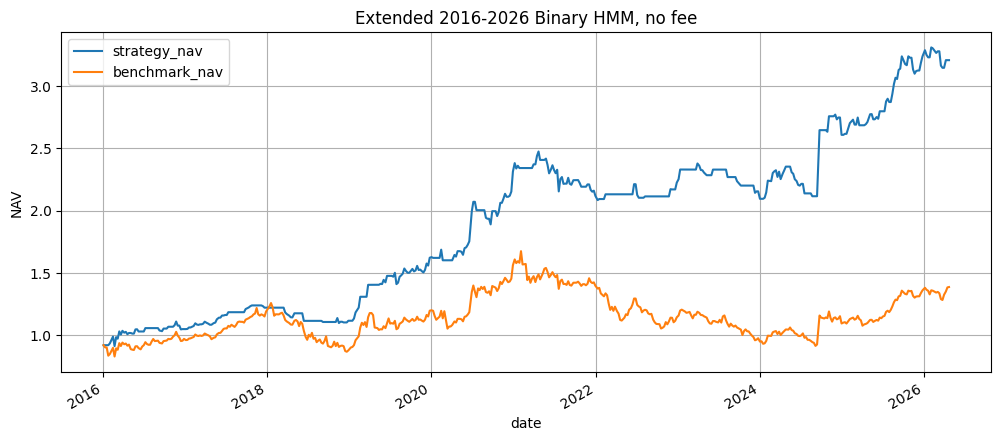

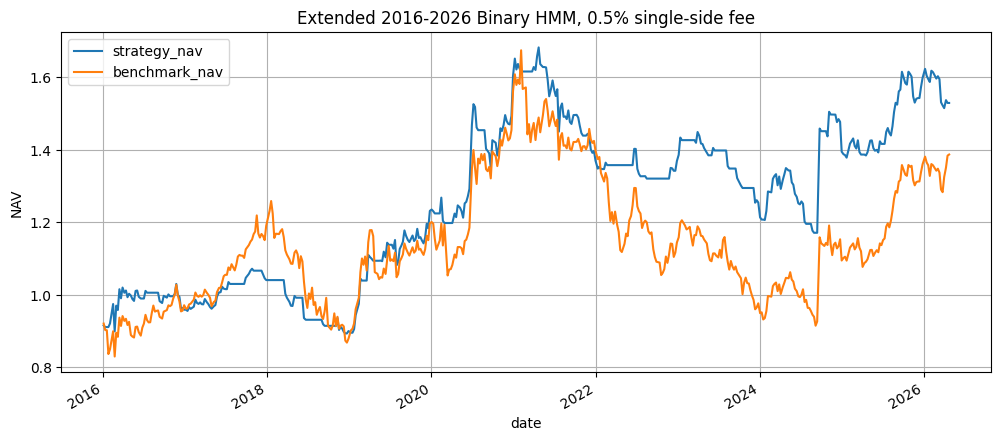

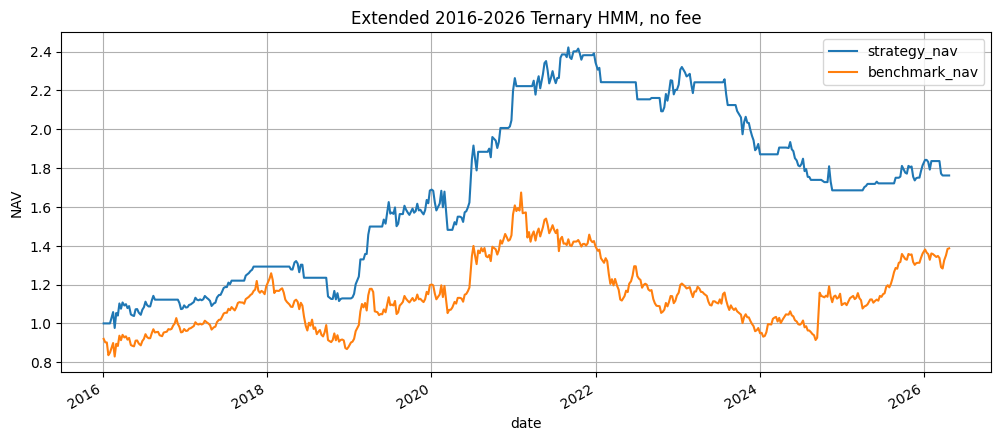

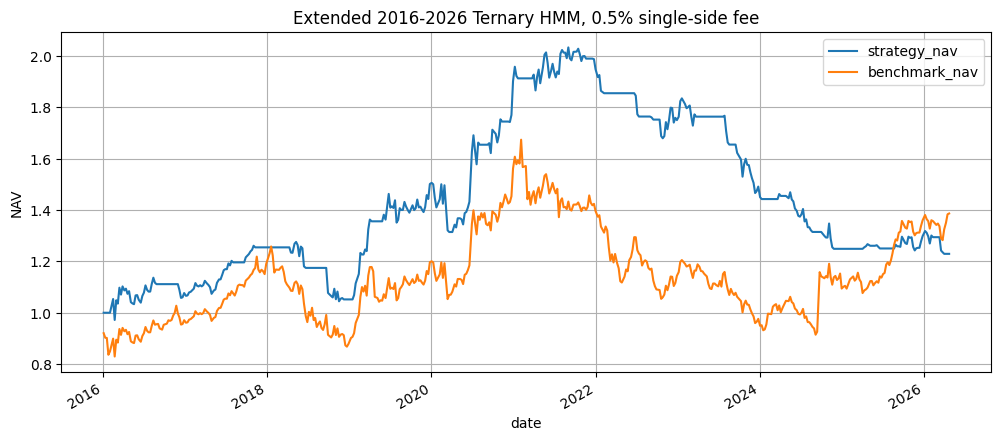

In [33]:
def plot_nav(bt: pd.DataFrame, title: str):
    if bt.empty:
        print(f"{title}: no prediction results")
        return
    ax = bt.set_index("date")[["strategy_nav", "benchmark_nav"]].plot(title=title)
    ax.set_ylabel("NAV")
    plt.show()

plot_nav(bt_extended_binary, "Extended 2016-2026 Binary HMM, no fee")
plot_nav(bt_extended_binary_fee, "Extended 2016-2026 Binary HMM, 0.5% single-side fee")
plot_nav(bt_extended_ternary, "Extended 2016-2026 Ternary HMM, no fee")
plot_nav(bt_extended_ternary_fee, "Extended 2016-2026 Ternary HMM, 0.5% single-side fee")
